In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("JetGuard - Data Exploration")

JetGuard - Data Exploration


In [2]:
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

print("Total columns:", len(columns))

Total columns: 26


In [5]:
DATA_DIR = Path(r"C:\\Users\\ahzam\Desktop\\Projects\\JetGuard\\dataset")

train_path = DATA_DIR / "train_FD001.txt"
test_path = DATA_DIR / "test_FD001.txt"
rul_path = DATA_DIR / "RUL_FD001.txt"

train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
print("RUL dataset:", rul_df.shape)

Training dataset: (20631, 26)
Testing dataset: (13096, 26)
RUL dataset: (100, 1)


In [7]:
train_df.head()
train_df.info()
train_df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

,count,mean,std,min,25%,50%,75%,max
engine_id,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


In [8]:
engine_cycles = (
    train_df.groupby("engine_id")["cycle"]
    .max()
)

print(engine_cycles.describe())

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


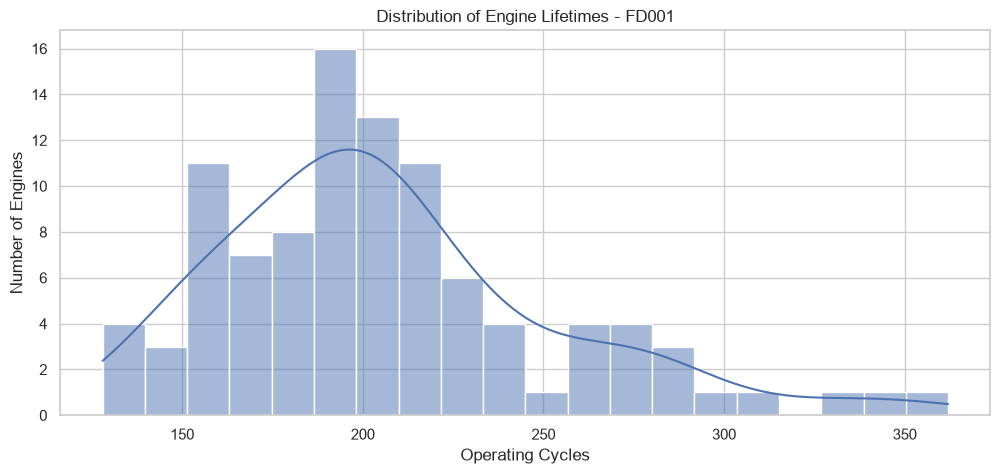

In [9]:
plt.figure(figsize=(12, 5))

sns.histplot(engine_cycles, bins=20, kde=True)

plt.title("Distribution of Engine Lifetimes - FD001")
plt.xlabel("Operating Cycles")
plt.ylabel("Number of Engines")

plt.show()

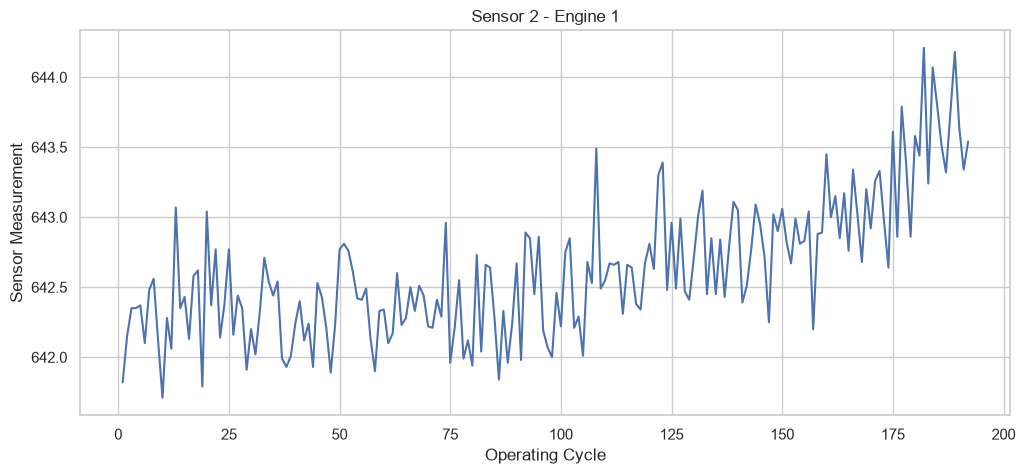

In [10]:
plt.figure(figsize=(12, 5))

engine_1 = train_df[train_df["engine_id"] == 1]

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"]
)

plt.title("Sensor 2 - Engine 1")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Measurement")

plt.show()

In [11]:
print("Missing values:")
print(train_df.isnull().sum().sum())

print("\nDuplicate records:")
print(train_df.duplicated().sum())

print("\nTest missing values:")
print(test_df.isnull().sum().sum())

Missing values:
0

Duplicate records:
0

Test missing values:
0


In [12]:
print("Training engines:",
      train_df["engine_id"].nunique())

print("Testing engines:",
      test_df["engine_id"].nunique())

print("\nTraining cycles per engine:")
print(train_df.groupby("engine_id")["cycle"].count().describe())

print("\nTesting cycles per engine:")
print(test_df.groupby("engine_id")["cycle"].count().describe())

Training engines: 100
Testing engines: 100

Training cycles per engine:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

Testing cycles per engine:
count    100.000000
mean     130.960000
std       53.593479
min       31.000000
25%       88.750000
50%      133.500000
75%      164.250000
max      303.000000
Name: cycle, dtype: float64


In [13]:
sensor_cols = [
    f"sensor_{i}" for i in range(1, 22)
]

sensor_variance = train_df[sensor_cols].var()

print("Sensor variance:")
print(sensor_variance.sort_values())

constant_sensors = sensor_variance[
    sensor_variance == 0
].index.tolist()

print("\nConstant sensors:")
print(constant_sensors)

Sensor variance:
sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.203765e-35
sensor_5     2.840037e-29
sensor_6     1.929279e-06
sensor_15    1.406628e-03
sensor_8     5.038938e-03
sensor_13    5.172330e-03
sensor_21    1.171825e-02
sensor_20    3.266927e-02
sensor_11    7.133568e-02
sensor_2     2.500533e-01
sensor_12    5.439850e-01
sensor_7     7.833883e-01
sensor_17    2.398667e+00
sensor_3     3.759099e+01
sensor_4     8.101089e+01
sensor_14    3.639005e+02
sensor_9     4.876536e+02
dtype: float64

Constant sensors:
['sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']


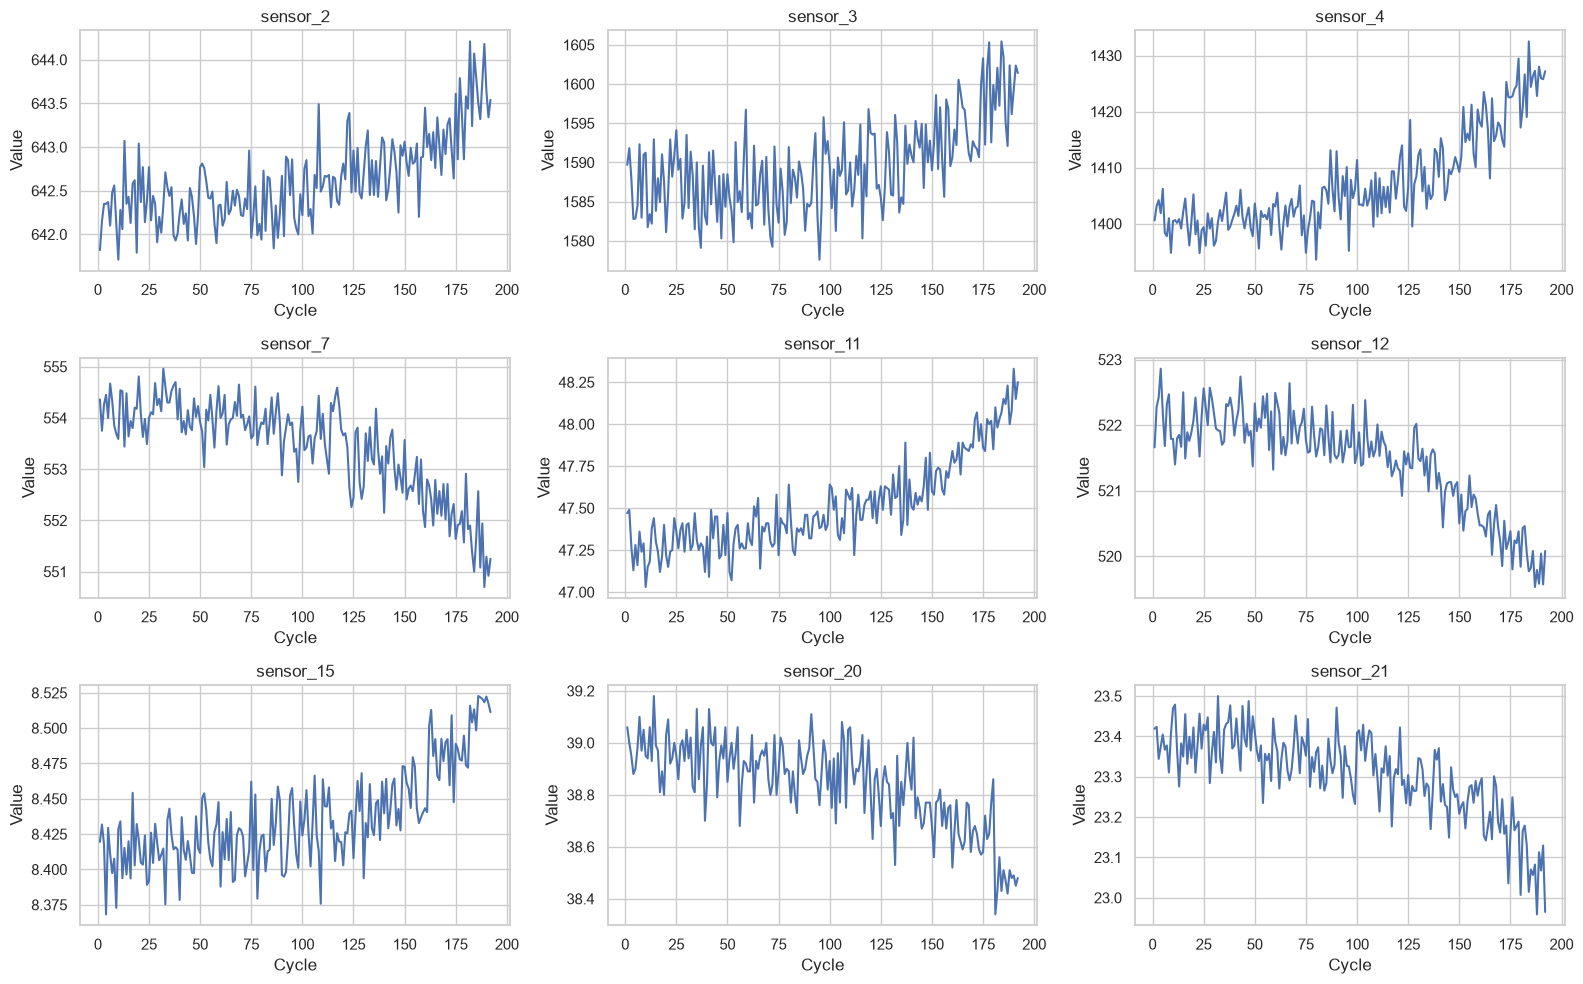

In [14]:
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12",
    "sensor_15",
    "sensor_20",
    "sensor_21"
]

engine_1 = train_df[
    train_df["engine_id"] == 1
]

fig, axes = plt.subplots(
    3, 3, figsize=(16, 10)
)

for sensor, ax in zip(selected_sensors, axes.flatten()):
    ax.plot(engine_1["cycle"], engine_1[sensor])
    ax.set_title(sensor)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

In [15]:
settings = [
    "setting_1",
    "setting_2",
    "setting_3"
]

print(train_df[settings].describe().T)

             count        mean       std       min       25%    50%       75%  \
setting_1  20631.0   -0.000009  0.002187   -0.0087   -0.0015    0.0    0.0015   
setting_2  20631.0    0.000002  0.000293   -0.0006   -0.0002    0.0    0.0003   
setting_3  20631.0  100.000000  0.000000  100.0000  100.0000  100.0  100.0000   

                max  
setting_1    0.0087  
setting_2    0.0006  
setting_3  100.0000  
